# 00 · Free radar data for S, C and X band, and what is wrong with each

**radar-wow core.** Every algorithm in the radar-wow repos runs on the same free data:

| name | band | radar | source |
|---|---|---|---|
| `nexrad_ktlx_s` | S | NWS WSR-88D KTLX, 20 May 2013 (Moore tornado) | NEXRAD Level II |
| `arm_csapr2_c` | C | ARM CSAPR2, Argentina, 11 Nov 2018 | ARM CfRadial |
| `imd_jaipur_c` | C | IMD Jaipur DWR, 22 Aug 2022 | IMD IRIS netCDF |
| `arm_xprecip_x` | X | ARM X-band precip radar, Colorado, 14 Mar 2022 | ARM CfRadial |
| `arm_xsapr_x` | X | ARM X-SAPR, Oklahoma, 20 May 2012 | CfRadial (Py-ART example) |

All files come from the openradar `open-radar-data` collection; `nexrad_aws()` fetches any other
NEXRAD volume from AWS. **Each radar arrives with its own problems**, so before any algorithm we
run `diagnose()`, which measures them and names the radar-wow stage that fixes each one.

In [1]:
# Colab: uncomment to install
!pip install -q "git+https://github.com/radar-wow/radarwow-core"

zsh:1: command not found: pip


In [2]:
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from radarwow.core import SAMPLES, diagnose, load_sample
from radarwow.core.noise import signal_mask
from radarwow.core.plotting import panel

FIG = "../docs/figures"

## 1. Known problems per source (from our checks)

In [3]:
for s in SAMPLES.values():
    display(Markdown(f"**{s.name}** · band {s.band} · {s.radar} · {s.when}\n\n" + "\n".join(f"- {k}" for k in s.known_issues)))

**nexrad_ktlx_s** · band S · NWS WSR-88D KTLX (Oklahoma City) · 2013-05-20 20:16 UTC

- Below-threshold and range-folded gates are stored as code values (DBZH -33/-32.5, ZDR -8, RHOHV 0.20): masked on read.
- PHIDP stored 0-360 deg with a ~36 deg system offset; 38 rays wrap past 360 (folding) in the lowest sweep.
- rhoHV > 1.02 on ~15 % of signal gates (no low-SNR cap).
- Reflectivity is already clutter-filtered (CMD) in the RDA; no total-power moment.
- Split cuts: reflectivity/dual-pol and velocity of the lowest tilt are separate sweeps.

**arm_csapr2_c** · band C · ARM CSAPR2 (Cordoba, Argentina, RELAMPAGO) · 2018-11-11 03:00 UTC

- Raw moments *and* ARM-CMAC corrected copies (corrected_*, filtered_*) in one file: test on raw, use corrected only as reference.
- Noise gates stored (not censored); the SNR field is biased (SNR > 3 dB on 98 % of gates vs NCP > 0.4 on 45 %).
- PHIDP 0-360 deg with a ~197 deg system offset and folding on 36 rays; it *decreases* with range in rain on 92 % of rays (reversed sign convention).
- C-band attenuation and differential attenuation in convective cores; ground clutter near the Sierras de Cordoba.

**arm_xprecip_x** · band X · ARM X-band precipitation radar (Gunnison, Colorado, SAIL) · 2022-03-14 02:15 UTC

- Noise gates stored: only ~25 % of gates are signal; 22 duplicate rays (0.32 deg azimuths).
- PHIDP system offset ~102 deg; mostly snow/mixed phase so KDP is small and rain relations do not apply.
- Mountain beam blockage (cumulative blockage flag included); raw plus CMAC-corrected copies in one file.

**arm_xsapr_x** · band X · ARM X-SAPR (SGP, Oklahoma; Py-ART example file) · 2012-05-20 06:41 UTC

- Older CfRadial with Py-ART-era field names; `diff_phase` is actually KDP (long_name specific_differential_phase_hv), PHIDP is `dp_phase_shift`.
- ZDR is never negative (clipped or unsigned storage): unusable for bias checks.
- Noise gates stored; PHIDP system offset ~119 deg with folding on 45 rays; heavy X-band attenuation behind cores.

**imd_jaipur_c** · band C · IMD Jaipur DWR (Vaisala C-band) · 2022-08-22 13:52 UTC

- No PHIDP, RHOHV or KDP exported: dual-pol QC, KDP and attenuation correction are impossible.
- Vendor HCLASS field present; Z already processed by IRIS (clutter filter, thresholds).
- Non-standard netCDF (FSL) needs the radar-wow adapter.

## 2. Look at each radar: raw moments, noise masked
Gates that are only receiver noise are hidden using `signal_mask` (SNR and NCP if the file has
them, otherwise the reflectivity noise floor). Note how different the five look.

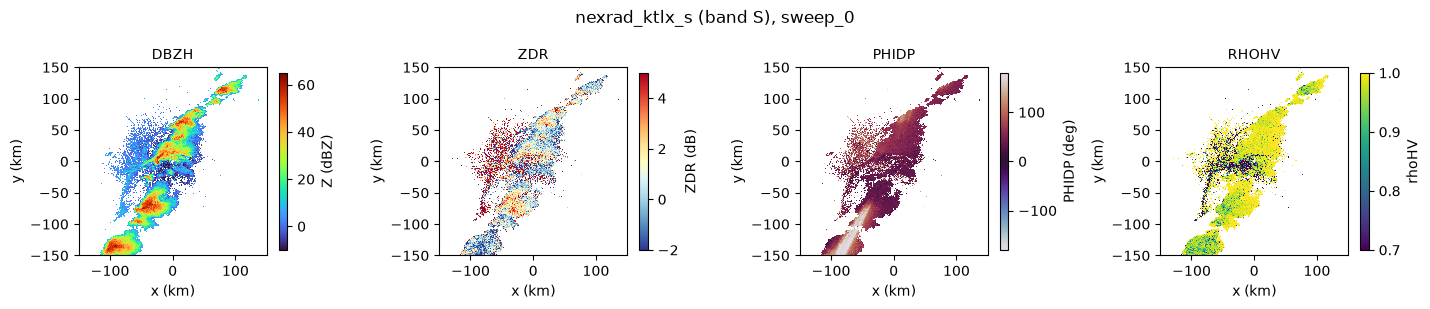

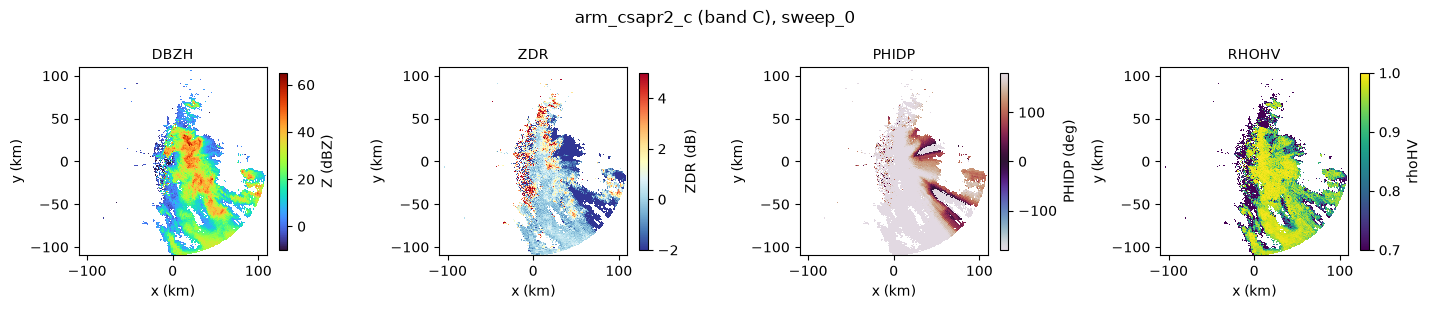

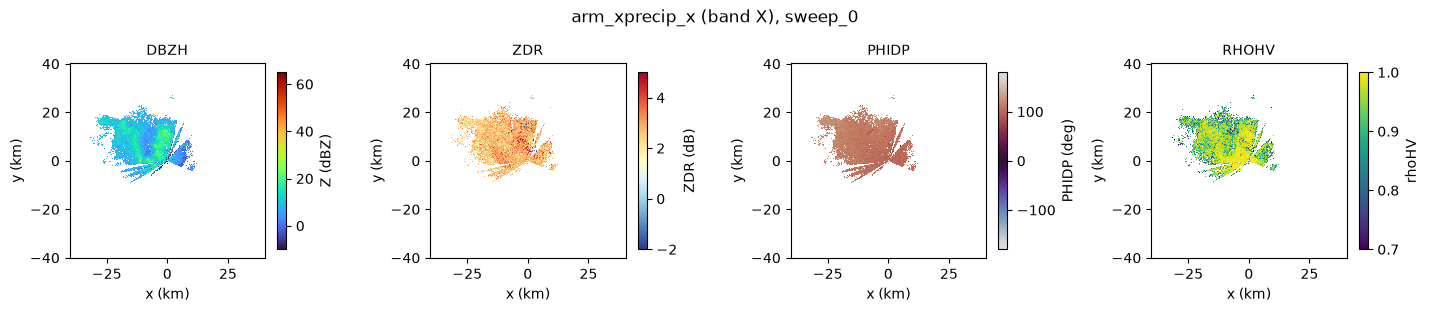

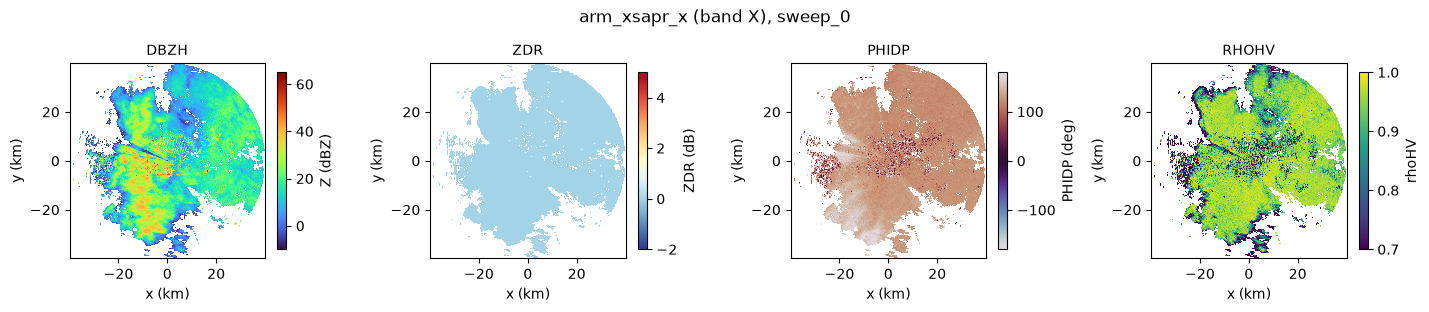

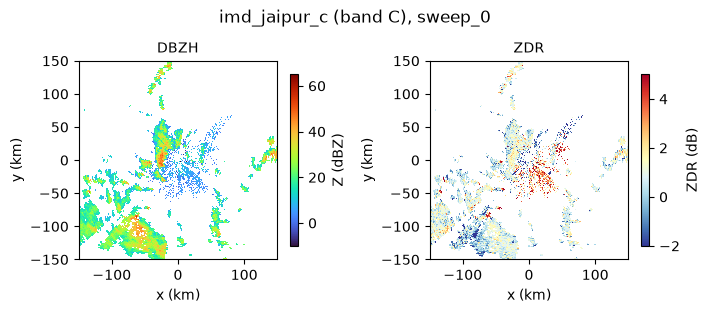

In [4]:
volumes = {name: load_sample(name) for name in SAMPLES}
reports = {}
for name, dt in volumes.items():
    rep = diagnose(dt)
    reports[name] = rep
    ds = dt[rep.sweep].to_dataset()
    sig = signal_mask(ds)
    shown = ds.copy()
    for m in ("DBZH", "ZDR", "PHIDP", "RHOHV"):
        if m in shown:
            shown[m] = shown[m].where(sig)
    span = float(ds["range"].values[-1]) / 1e3
    fig = panel(shown, [m for m in ("DBZH", "ZDR", "PHIDP", "RHOHV") if m in shown] or ["DBZH"],
                max_km=min(span, 150), suptitle=f"{name} (band {SAMPLES[name].band}), {rep.sweep}", size=3.6)
    fig.savefig(f"{FIG}/00_{name}.png", dpi=110)
    plt.show()

## 3. Health checks: the problems, measured
Severity: **blocker** (an algorithm family cannot run), **fix** (must be corrected first),
**check** (inspect), **info**.

In [5]:
for name, rep in reports.items():
    display(Markdown(rep.to_markdown()))

**nexrad_ktlx_s** (band S, sweep_0)

| severity | topic | finding | remedy |
|---|---|---|---|
| fix | PHIDP | system PHIDP offset ~36 deg (median of first rain gates) | kdp: subtract offset / use offset-free derivative (Vulpiani 2012) |
| fix | PHIDP | 38 rays with a > 180 deg drop (folding) | kdp: unfold (Vulpiani 2012) |
| check | rhoHV | 15.5% of signal gates rhoHV > 1.02 (noise-correction/calibration issue) | check SNR-dependent rhoHV correction |
| info | censoring | NEXRAD below-threshold / range-folded codes set to missing: ZDR=-8,-7.9375, RHOHV=0.201667,0.205, DBZH=-33,-32.5, PHIDP=-0.705194,-0.352597 | handled by core.open_volume |
| info | ZDR | median ZDR in light rain +0.50 dB: no large bias |  |

**arm_csapr2_c** (band C, sweep_0)

| severity | topic | finding | remedy |
|---|---|---|---|
| fix | geometry | 0 azimuth gaps and 1 duplicate rays (resolution 0.99 deg) | regrid azimuths before texture/KDP filters (core.geometry) |
| fix | noise | noise gates are stored, not censored (floor ~-46 dBZ at 1 km, rising 20 log r); 45% of gates are signal | qc: signal mask (SNR or noise-floor + 3 dB) before any other step |
| fix | PHIDP | system PHIDP offset ~197 deg (median of first rain gates) | kdp: subtract offset / use offset-free derivative (Vulpiani 2012) |
| fix | PHIDP | 36 rays with a > 180 deg drop (folding) | kdp: unfold (Vulpiani 2012) |
| fix | PHIDP | PHIDP decreases with range in rain on 92% of rays (reversed sign convention) | kdp: flip sign before processing (done automatically in radarwow.kdp) |
| check | noise | SNR > 3 dB on 98% of gates but NCP/SQI > 0.4 on only 45%: SNR field looks biased | signal mask uses both (core.noise.signal_mask) |
| info | provenance | 10 pre-processed fields in file (e.g. attenuation_corrected_differential_reflectivity, attenuation_corrected_differential_reflectivity_lag_1, attenuation_corrected_reflectivity_h) | test algorithms on raw moments; use these only as a reference |
| info | ZDR | median ZDR in light rain +0.03 dB: no large bias |  |

**arm_xprecip_x** (band X, sweep_0)

| severity | topic | finding | remedy |
|---|---|---|---|
| fix | geometry | 0 azimuth gaps and 22 duplicate rays (resolution 0.32 deg) | regrid azimuths before texture/KDP filters (core.geometry) |
| fix | noise | noise gates are stored, not censored (floor ~-31 dBZ at 1 km, rising 20 log r); 25% of gates are signal | qc: signal mask (SNR or noise-floor + 3 dB) before any other step |
| fix | PHIDP | system PHIDP offset ~102 deg (median of first rain gates) | kdp: subtract offset / use offset-free derivative (Vulpiani 2012) |
| info | provenance | 7 pre-processed fields in file (e.g. corrected_differential_phase, corrected_differential_reflectivity, corrected_reflectivity) | test algorithms on raw moments; use these only as a reference |
| info | ZDR | too few light-rain gates for the ZDR bias check on this sweep |  |

**arm_xsapr_x** (band X, sweep_0)

| severity | topic | finding | remedy |
|---|---|---|---|
| fix | noise | noise gates are stored, not censored (floor ~-34 dBZ at 1 km, rising 20 log r); 77% of gates are signal | qc: signal mask (SNR or noise-floor + 3 dB) before any other step |
| fix | interference | 2 rays with signal on > 90 % of gates beyond 30 km (emitter-spike signature) | qc: interference detection (Saltikoff 2016 signature) |
| fix | PHIDP | system PHIDP offset ~119 deg (median of first rain gates) | kdp: subtract offset / use offset-free derivative (Vulpiani 2012) |
| fix | PHIDP | 45 rays with a > 180 deg drop (folding) | kdp: unfold (Vulpiani 2012) |
| fix | ZDR | ZDR is never negative on signal gates: clipped or stored unsigned | treat ZDR as unusable for bias checks and R(Z,ZDR) until the storage is understood |
| info | provenance | 4 pre-processed fields in file (e.g. corrected_reflectivity_horizontal, proc_dp_phase_shift, recalculated_diff_phase) | test algorithms on raw moments; use these only as a reference |

**imd_jaipur_c** (band C, sweep_0)

| severity | topic | finding | remedy |
|---|---|---|---|
| blocker | moments | PHIDP missing: no KDP, no PHIDP-based attenuation correction, no R(KDP)/R(A) | request the moment from the operator; fall back to single-pol chain |
| blocker | moments | RHOHV missing: no dual-pol QC or hydrometeor classification | request the moment from the operator; fall back to single-pol chain |
| info | clutter | both total (DBTH) and filtered (DBZH) reflectivity present | DBTH - DBZH = clutter power removed by the signal processor |

## 4. Summary table

In [6]:
cols = ["frac_signal", "phidp_system_offset", "rays_with_folding", "zdr_median_light_rain", "rhohv_gt_1.02", "interference_rays"]
rows = ["| sample | band | " + " | ".join(cols) + " |", "|---|---|" + "---|" * len(cols)]
for name, rep in reports.items():
    rows.append(f"| {name} | {SAMPLES[name].band} | " + " | ".join(str(rep.numbers.get(c, "-")) for c in cols) + " |")
display(Markdown("\n".join(rows)))

| sample | band | frac_signal | phidp_system_offset | rays_with_folding | zdr_median_light_rain | rhohv_gt_1.02 | interference_rays |
|---|---|---|---|---|---|---|---|
| nexrad_ktlx_s | S | 0.148 | 36.0 | 38 | 0.5 | 0.1552 | 0 |
| arm_csapr2_c | C | 0.449 | 196.7 | 36 | 0.03 | 0.0 | 0 |
| arm_xprecip_x | X | 0.252 | 102.0 | 0 | - | 0.0 | 0 |
| arm_xsapr_x | X | 0.775 | 118.9 | 45 | - | 0.0 | 2 |
| imd_jaipur_c | C | 0.145 | - | - | - | - | 0 |

## What this tells us
- **No two sources share the same problems.** NEXRAD stores "below threshold" as a number;
  ARM files store noise and ship corrected copies next to the raw fields; the CSAPR2 SNR field
  is biased; PHIDP offsets range from 0 to ~200 deg and some sources wrap at 360 deg; one ZDR
  field is clipped at 0; the IMD file has no PHIDP or rhoHV at all.
- So every radar-wow pipeline starts with `open_volume` (format + names + codes) and
  `diagnose` (measured problems), and each algorithm declares which moments and bands it needs.